# HumanEval baseline — LangGraph + Ollama (qwen2.5-coder:7b)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (7, 4)})
PASS, FAIL = "#2a78d6", "#eb6834"

df = pd.read_json("results/baseline.jsonl", lines=True)
df["n"] = df.task_id.str.split("/").str[1].astype(int)
df.head()

,task_id,passed,error,seconds,tool_calls,output_tokens,prompt_len,code_len,n
0,HumanEval/0,True,ok,0.935572,1,87,348,279,0
1,HumanEval/1,True,ok,1.454281,1,137,506,487,1
2,HumanEval/2,True,ok,0.462615,1,39,331,96,2
3,HumanEval/3,True,ok,0.801090,1,70,448,216,3
4,HumanEval/4,True,ok,1.180123,1,111,430,298,4


In [2]:
print(f"pass@1: {df.passed.mean():.3f} ({df.passed.sum()}/{len(df)})")
df[["seconds", "output_tokens", "code_len"]].describe().round(2)

pass@1: 0.799 (131/164)


,seconds,output_tokens,code_len
count,164.00,164.00,164.00
mean,1.16,101.87,236.93
std,0.68,63.00,168.91
min,0.00,0.00,0.00
25%,0.73,60.00,128.50
50%,1.00,86.00,216.50
75%,1.42,125.25,317.25
max,4.78,446.00,995.00


## Passed vs failed

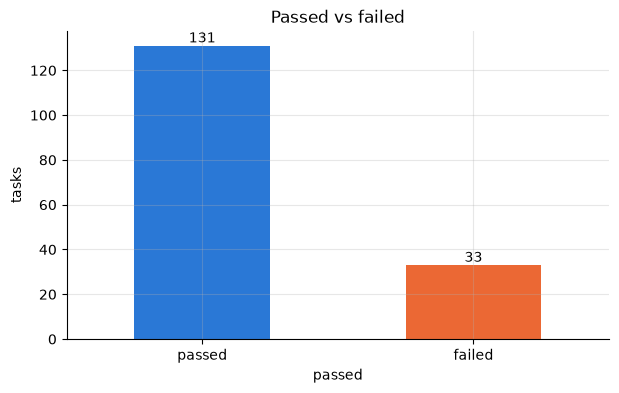

In [3]:
counts = df.passed.map({True: "passed", False: "failed"}).value_counts().reindex(["passed", "failed"])
ax = counts.plot.bar(color=[PASS, FAIL], rot=0)
ax.bar_label(ax.containers[0])
ax.set_ylabel("tasks")
ax.set_title("Passed vs failed")
plt.show()

## Failure types

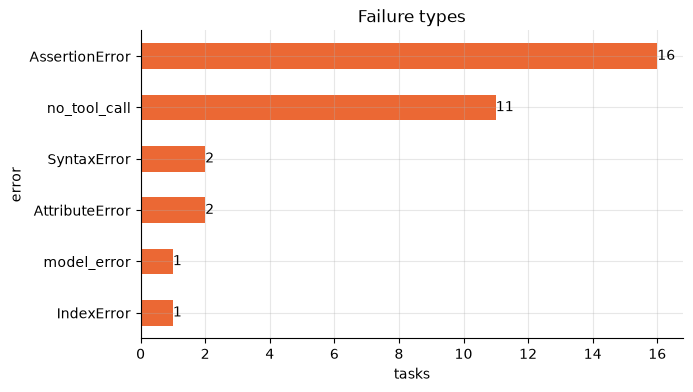

In [4]:
errors = df[~df.passed].error.value_counts().sort_values()
ax = errors.plot.barh(color=FAIL)
ax.bar_label(ax.containers[0])
ax.set_xlabel("tasks")
ax.set_title("Failure types")
plt.show()

## Time per task

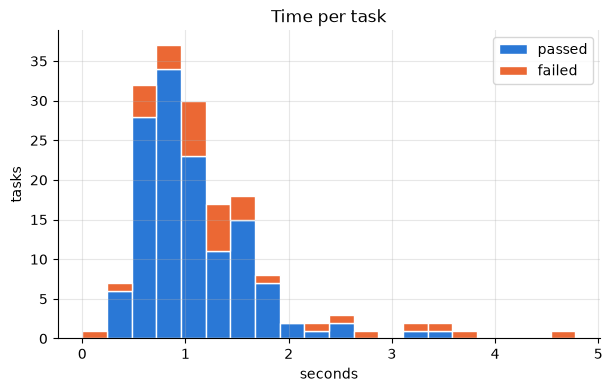

In [5]:
bins = 20
plt.hist([df[df.passed].seconds, df[~df.passed].seconds], bins=bins, stacked=True, color=[PASS, FAIL], label=["passed", "failed"], edgecolor="white")
plt.xlabel("seconds")
plt.ylabel("tasks")
plt.title("Time per task")
plt.legend()
plt.show()

## Pass rate by prompt length

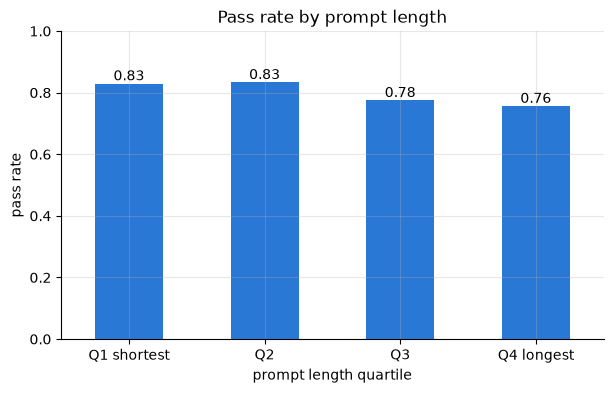

In [6]:
df["prompt_bin"] = pd.qcut(df.prompt_len, 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])
rate = df.groupby("prompt_bin", observed=True).passed.mean()
ax = rate.plot.bar(color=PASS, rot=0)
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_ylim(0, 1)
ax.set_xlabel("prompt length quartile")
ax.set_ylabel("pass rate")
ax.set_title("Pass rate by prompt length")
plt.show()

## Pass rate along the benchmark

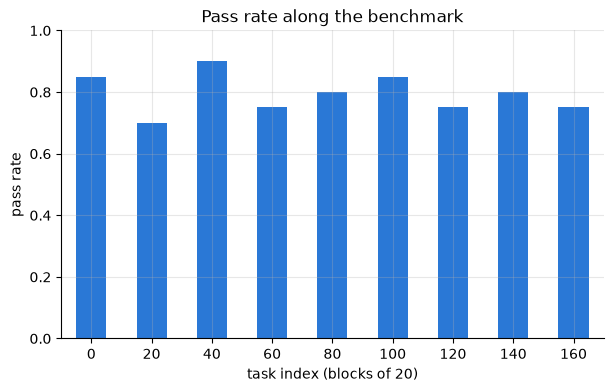

In [7]:
df["block"] = df.n // 20 * 20
rate = df.groupby("block").passed.mean()
ax = rate.plot.bar(color=PASS, rot=0)
ax.set_ylim(0, 1)
ax.set_xlabel("task index (blocks of 20)")
ax.set_ylabel("pass rate")
ax.set_title("Pass rate along the benchmark")
plt.show()

## Output tokens vs time

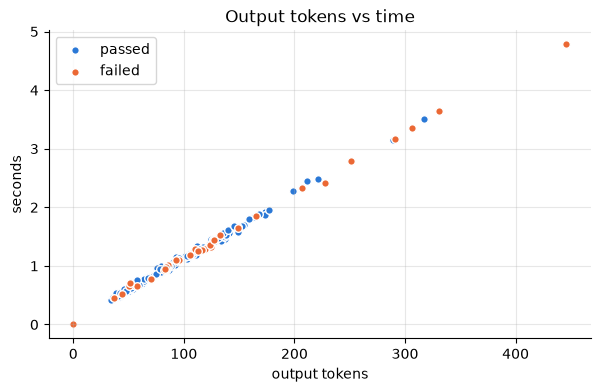

In [8]:
for passed, color, label in [(True, PASS, "passed"), (False, FAIL, "failed")]:
    part = df[df.passed == passed]
    plt.scatter(part.output_tokens, part.seconds, s=30, color=color, label=label, edgecolor="white", linewidth=1)
plt.xlabel("output tokens")
plt.ylabel("seconds")
plt.title("Output tokens vs time")
plt.legend()
plt.show()

## Failed tasks

In [9]:
df[~df.passed][["task_id", "error", "seconds", "output_tokens", "code_len"]]

,task_id,error,seconds,output_tokens,code_len
6,HumanEval/6,SyntaxError,1.326631,125,416
10,HumanEval/10,no_tool_call,2.418526,228,0
19,HumanEval/19,model_error,0.000000,0,0
22,HumanEval/22,SyntaxError,0.662753,58,154
24,HumanEval/24,no_tool_call,1.285736,119,0
26,HumanEval/26,AssertionError,1.276907,116,329
32,HumanEval/32,AssertionError,3.651977,331,995
38,HumanEval/38,no_tool_call,3.345815,306,0
39,HumanEval/39,AssertionError,3.170540,291,816
50,HumanEval/50,no_tool_call,1.860117,165,0
